<a href="https://colab.research.google.com/github/Swaroop2108/Deep-Learning/blob/main/DL_Skill1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
!pip install -q tensorflow numpy matplotlib pillow scikit-learn

In [12]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from PIL import Image
from google.colab import files
from IPython.display import display, HTML
from tensorflow.keras.applications.mobilenet_v2 import (
    MobileNetV2,
    preprocess_input,
    decode_predictions
)

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: []


In [13]:
display(HTML("""
<div style="
background:linear-gradient(120deg,#07152e,#075985);
padding:30px;
border-radius:15px;
text-align:center;
color:white;">

<h1 style="font-size:42px;color:#38bdf8;">
VISIONPORT AI
</h1>

<h3>Deep Learning System Lifecycle Mapping</h3>

<p>Intelligent Image Classification Platform</p>

<p>Powered by Python | TensorFlow | CNN | MobileNetV2</p>

</div>
"""))



In [14]:
print("Loading MobileNetV2 model...")

model = MobileNetV2(
    weights="imagenet",
    include_top=True,
    input_shape=(224,224,3)
)

print("VisionPort Model Loaded Successfully!")


Loading MobileNetV2 model...
VisionPort Model Loaded Successfully!


In [15]:

def preprocess_image(image):

    image = image.convert("RGB")

    image = image.resize((224,224))

    image_array = np.array(image)

    image_array = np.expand_dims(
        image_array,
        axis=0
    )

    image_array = preprocess_input(image_array)

    return image_array

print("Image preprocessing module ready!")


Image preprocessing module ready!


In [16]:
def predict_image(image):

    processed_image = preprocess_image(image)

    predictions = model.predict(
        processed_image,
        verbose=0
    )

    results = decode_predictions(
        predictions,
        top=5
    )[0]

    return results

print("Prediction engine ready!")

Prediction engine ready!


Upload an image for VisionPort analysis


Saving lambo.jpeg to lambo (1).jpeg


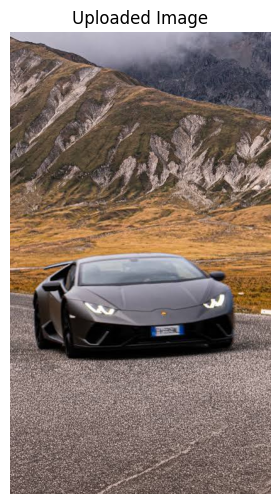

In [17]:
print("Upload an image for VisionPort analysis")

uploaded = files.upload()

image_name = list(uploaded.keys())[0]

image = Image.open(image_name).convert("RGB")

plt.figure(figsize=(6,6))
plt.imshow(image)
plt.title("Uploaded Image")
plt.axis("off")
plt.show()


In [18]:

results = predict_image(image)

best_prediction = results[0]

predicted_class = best_prediction[1].replace("_"," ").title()

confidence = float(best_prediction[2]) * 100

print("=" * 45)
print("       VISIONPORT AI ANALYSIS")
print("=" * 45)

print("Predicted Object:", predicted_class)

print("Confidence Score:", round(confidence,2), "%")

print("=" * 45)

print("\nTOP 5 PREDICTIONS\n")

for _, label, score in results:

    print(
        label.replace("_"," ").title(),
        ":", round(float(score)*100,2), "%"
    )


       VISIONPORT AI ANALYSIS
Predicted Object: Sports Car
Confidence Score: 57.52 %

TOP 5 PREDICTIONS

Sports Car : 57.52 %
Car Wheel : 6.18 %
Beach Wagon : 5.1 %
Convertible : 3.71 %
Minivan : 3.62 %


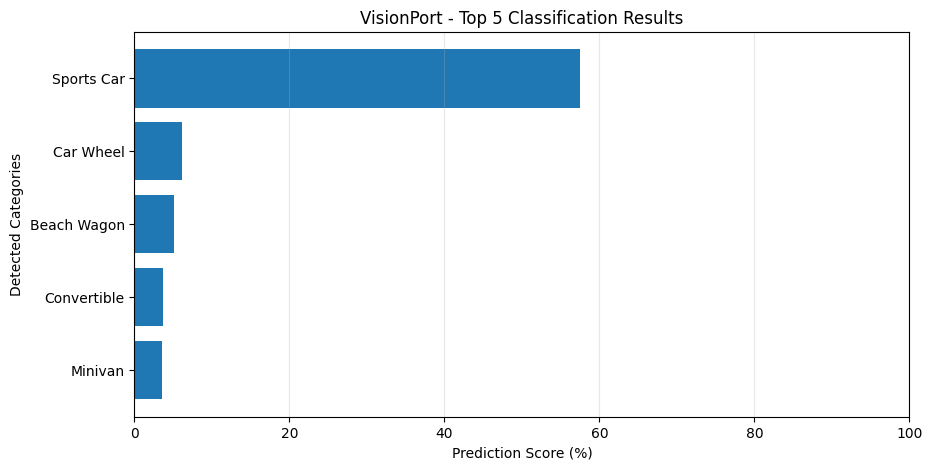

In [19]:

labels = [
    item[1].replace("_"," ").title()
    for item in results
]

scores = [
    float(item[2])*100
    for item in results
]

plt.figure(figsize=(10,5))

plt.barh(labels[::-1], scores[::-1])

plt.xlabel("Prediction Score (%)")

plt.ylabel("Detected Categories")

plt.title("VisionPort - Top 5 Classification Results")

plt.xlim(0,100)

plt.grid(axis="x", alpha=0.3)

plt.show()



In [20]:

from IPython.display import display, HTML

display(HTML("""
<div style="
background:#0b1729;
color:white;
padding:25px;
border-radius:15px;
font-family:Arial;">

<h2 style="text-align:center;color:#38bdf8;">
VISIONPORT - SYSTEM LIFECYCLE
</h2>

"""+ "".join([
f"""
<div style="
background:#173654;
padding:15px;
margin:10px auto;
border-radius:10px;
text-align:center;
max-width:600px;">

<h3>{step}</h3>
<p>{description}</p>

</div>
<div style="text-align:center;color:#38bdf8;font-size:24px;">↓</div>
"""
for step, description in [
("1. Data Collection","Upload image dataset"),
("2. Preprocessing","Resize and normalize images"),
("3. Feature Extraction","CNN extracts visual features"),
("4. Model Processing","MobileNetV2 processes image"),
("5. Classification","Predict image category"),
("6. Evaluation","Analyze prediction scores"),
("7. Deployment","Deliver AI results")
]
])+"""
</div>
"""))
